## Live Deployment Link (Task 2 - Heart Disease Prediction System)

**Live demo:** `PASTE-YOUR-LIVE-STREAMLIT-LINK-HERE`

In [1]:
# Step 1: Import Libraries

# Import numerical computing library (used for arrays, math operations, etc.)
import numpy as np

# Import data manipulation library (used for DataFrames, reading/writing data, etc.)
import pandas as pd

# Import pickle (used for saving and loading Python objects/models)
import pickle

# Import train_test_split (divide dataset into training/testing sets) and
# cross_val_score / StratifiedKFold (extra cross-validation check in Step 7.6)
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold

# Import LabelEncoder (used to convert categorical values into numeric codes)
from sklearn.preprocessing import LabelEncoder

# Import mutual_info_classif (used in Step 4 to rank attributes by usefulness)
from sklearn.feature_selection import mutual_info_classif

# Import Support Vector Machine (SVM) model from scikit-learn
from sklearn import svm

# Import evaluation metrics
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Import PrettyTable (used to display results in a clean, table format)
from prettytable import PrettyTable

# Import plotting libraries (used for the confusion matrix heatmap)
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
# Step 2: Load Sample Data

# The 14 attributes of the Cleveland dataset, in file order
column_names = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
                "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num"]

# Read the file; 'processed.cleveland.data' should be present in the working directory
raw_data = pd.read_csv("processed.cleveland.data", header=None, names=column_names, na_values="?")

# Print a header to indicate that the data is being displayed
print("\n\nRaw Data (first 10 rows):")
print("==========================\n")

# Configure pandas to display all columns (so nothing gets hidden with '...')
pd.set_option("display.max_rows", None, "display.max_columns", None)

# Print the first 10 rows (the full file has 303 rows)
print(raw_data.head(10))




Raw Data (first 10 rows):

    age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
0  63.0  1.0  1.0     145.0  233.0  1.0      2.0    150.0    0.0      2.3   
1  67.0  1.0  4.0     160.0  286.0  0.0      2.0    108.0    1.0      1.5   
2  67.0  1.0  4.0     120.0  229.0  0.0      2.0    129.0    1.0      2.6   
3  37.0  1.0  3.0     130.0  250.0  0.0      0.0    187.0    0.0      3.5   
4  41.0  0.0  2.0     130.0  204.0  0.0      2.0    172.0    0.0      1.4   
5  56.0  1.0  2.0     120.0  236.0  0.0      0.0    178.0    0.0      0.8   
6  62.0  0.0  4.0     140.0  268.0  0.0      2.0    160.0    0.0      3.6   
7  57.0  0.0  4.0     120.0  354.0  0.0      0.0    163.0    1.0      0.6   
8  63.0  1.0  4.0     130.0  254.0  0.0      2.0    147.0    0.0      1.4   
9  53.0  1.0  4.0     140.0  203.0  1.0      2.0    155.0    1.0      3.1   

   slope   ca  thal  num  
0    3.0  0.0   6.0    0  
1    2.0  3.0   3.0    2  
2    2.0  2.0   7.0    1  
3    3.0  0.0  

In [3]:
# Step 3.1: Understand Sample Data

# Print a header for clarity
print("\n\nAttributes in Raw Data:")
print("=======================\n")

# Display all column names (attributes) in the dataset
print(raw_data.columns)

# Print a header for instance count
print("\n\nNumber of Instances in Raw Data:", raw_data["age"].count())
print("=================================\n")

# Count missing values in each attribute
print("Missing values per attribute:")
print("=============================\n")
print(raw_data.isnull().sum())

# 'num' is the diagnosis: 0 = no heart disease, 1-4 = heart disease of increasing severity
print("\n\nDistribution of the diagnosis attribute 'num':")
print("==============================================\n")
print(raw_data["num"].value_counts().sort_index())




Attributes in Raw Data:

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num'],
      dtype='object')


Number of Instances in Raw Data: 303

Missing values per attribute:

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64


Distribution of the diagnosis attribute 'num':

num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64


In [4]:
# Step 3.2: Pre-process Sample Data

# Remove rows with missing values (6 rows in total)
clean_data = raw_data.dropna().reset_index(drop=True)

# Convert diagnosis (0-4) into Yes/No: 0 -> No, 1/2/3/4 -> Yes
clean_data["HeartDisease"] = np.where(clean_data["num"] > 0, "Yes", "No")

print("Rows before cleaning:", len(raw_data))
print("Rows after cleaning :", len(clean_data))
print("Rows removed        :", len(raw_data) - len(clean_data))

print("\n\nOutput attribute (HeartDisease) after pre-processing:")
print("=====================================================\n")
print(clean_data["HeartDisease"].value_counts())


Rows before cleaning: 303
Rows after cleaning : 297
Rows removed        : 6


Output attribute (HeartDisease) after pre-processing:

HeartDisease
No     160
Yes    137
Name: count, dtype: int64




Attribute Ranking (Mutual Information with HeartDisease):

thal       0.146
cp         0.137
ca         0.128
exang      0.092
slope      0.075
sex        0.040
restecg    0.016
fbs        0.000
dtype: float64


Selected 4 input attributes: ['thal', 'cp', 'ca', 'exang']


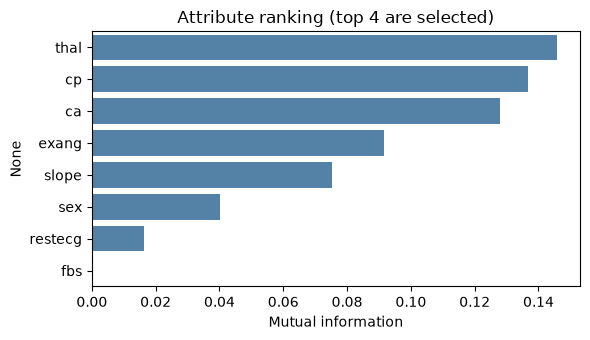



Sample Data (first 10 rows):

          ChestPain ExerciseAngina MajorVessels        Thalassemia  \
0    Typical Angina             No    0 Vessels       Fixed Defect   
1      Asymptomatic            Yes    3 Vessels             Normal   
2      Asymptomatic            Yes    2 Vessels  Reversible Defect   
3  Non-anginal Pain             No    0 Vessels             Normal   
4   Atypical Angina             No    0 Vessels             Normal   
5   Atypical Angina             No    0 Vessels             Normal   
6      Asymptomatic             No    2 Vessels             Normal   
7      Asymptomatic            Yes    0 Vessels             Normal   
8      Asymptomatic             No     1 Vessel  Reversible Defect   
9      Asymptomatic            Yes    0 Vessels  Reversible Defect   

  HeartDisease  
0           No  
1          Yes  
2          Yes  
3           No  
4           No  
5           No  
6          Yes  
7           No  
8          Yes  
9          Yes  

Saved: sa

In [5]:
# Step 4: Feature Extraction

# Candidate (categorical) attributes
candidate_columns = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]

# Mutual information between each candidate attribute and the output (Yes=1 / No=0)
target = (clean_data["HeartDisease"] == "Yes").astype(int)
mutual_info = mutual_info_classif(clean_data[candidate_columns], target,
                                  discrete_features=True, random_state=0)

ranking = pd.Series(mutual_info, index=candidate_columns).sort_values(ascending=False)

print("\n\nAttribute Ranking (Mutual Information with HeartDisease):")
print("=========================================================\n")
print(ranking.round(3))

# Keep the 4 best attributes
selected_columns = list(ranking.index[:4])
print("\n\nSelected 4 input attributes:", selected_columns)

# Plot the ranking so the choice is easy to see
plt.figure(figsize=(6, 3.5))
sns.barplot(x=ranking.values, y=ranking.index, color="steelblue")
plt.xlabel("Mutual information")
plt.title("Attribute ranking (top 4 are selected)")
plt.tight_layout()
plt.show()

# Convert numeric codes into readable words (meaning from the UCI dataset description)
sample_data = pd.DataFrame({
    "ChestPain": clean_data["cp"].map({1: "Typical Angina", 2: "Atypical Angina",
                                       3: "Non-anginal Pain", 4: "Asymptomatic"}),
    "ExerciseAngina": clean_data["exang"].map({0: "No", 1: "Yes"}),
    "MajorVessels": clean_data["ca"].map({0: "0 Vessels", 1: "1 Vessel",
                                          2: "2 Vessels", 3: "3 Vessels"}),
    "Thalassemia": clean_data["thal"].map({3: "Normal", 6: "Fixed Defect",
                                           7: "Reversible Defect"}),
    "HeartDisease": clean_data["HeartDisease"],
})

# Safety check: the 4 readable inputs must be exactly the 4 selected attributes
assert set(selected_columns) == {"cp", "exang", "ca", "thal"}, "Selected attributes changed - update the mapping above"

# Save the final Sample Data
sample_data.to_csv(r"sample-data.csv", index=False, header=True)

print("\n\nSample Data (first 10 rows):")
print("============================\n")
print(sample_data.head(10))
print("\nSaved: sample-data.csv  (shape:", sample_data.shape, ")")


In [6]:
# Step 5.1: Train the Label Encoder

# Define label categories for each feature
# These are all possible values each column can have in the dataset
chest_pain = pd.DataFrame({"ChestPain": ["Typical Angina", "Atypical Angina", "Non-anginal Pain", "Asymptomatic"]})
exercise_angina = pd.DataFrame({"ExerciseAngina": ["Yes", "No"]})
major_vessels = pd.DataFrame({"MajorVessels": ["0 Vessels", "1 Vessel", "2 Vessels", "3 Vessels"]})
thalassemia = pd.DataFrame({"Thalassemia": ["Normal", "Fixed Defect", "Reversible Defect"]})
heart_disease = pd.DataFrame({"HeartDisease": ["Yes", "No"]})

# Create LabelEncoder objects for each categorical column
chest_pain_label_encoder = LabelEncoder()
exercise_angina_label_encoder = LabelEncoder()
major_vessels_label_encoder = LabelEncoder()
thalassemia_label_encoder = LabelEncoder()
heart_disease_label_encoder = LabelEncoder()

# Train (fit) the encoders on the given categories
# np.ravel() flattens the DataFrame column into a 1D array for the encoder
chest_pain_label_encoder.fit(np.ravel(chest_pain))
exercise_angina_label_encoder.fit(np.ravel(exercise_angina))
major_vessels_label_encoder.fit(np.ravel(major_vessels))
thalassemia_label_encoder.fit(np.ravel(thalassemia))
heart_disease_label_encoder.fit(np.ravel(heart_disease))

# Show the numeric code given to every category (LabelEncoder numbers them in sorted order)
for name, encoder in [("ChestPain", chest_pain_label_encoder),
                      ("ExerciseAngina", exercise_angina_label_encoder),
                      ("MajorVessels", major_vessels_label_encoder),
                      ("Thalassemia", thalassemia_label_encoder),
                      ("HeartDisease", heart_disease_label_encoder)]:
    print(name, "->", {category: int(code) for code, category in enumerate(encoder.classes_)})


ChestPain -> {'Asymptomatic': 0, 'Atypical Angina': 1, 'Non-anginal Pain': 2, 'Typical Angina': 3}
ExerciseAngina -> {'No': 0, 'Yes': 1}
MajorVessels -> {'0 Vessels': 0, '1 Vessel': 1, '2 Vessels': 2, '3 Vessels': 3}
Thalassemia -> {'Fixed Defect': 0, 'Normal': 1, 'Reversible Defect': 2}
HeartDisease -> {'No': 0, 'Yes': 1}


In [7]:
# Step 5.2: Label Encode the Output

# Create copies of the dataset (one for encoded output, one to keep original)
sample_data_encoded_output = sample_data.copy()
original_sample_data = sample_data.copy()

# Transform "HeartDisease" (categorical -> numeric) using the trained LabelEncoder
print("\n\nHeartDisease Attribute After Label Encoding (first 10 rows):")
print("============================================================\n")
sample_data["encoded_heartdisease"] = heart_disease_label_encoder.transform(sample_data["HeartDisease"])

# Show original "HeartDisease" values and their numeric encodings
print(sample_data[["HeartDisease", "encoded_heartdisease"]].head(10))

# Replace the original output column with its encoded values
sample_data_encoded_output[["HeartDisease"]] = sample_data[["encoded_heartdisease"]]

# Save the encoded dataset to a CSV file (useful for training/testing later)
sample_data_encoded_output.to_csv(r"sample-data-encoded-output.csv", index=False, header=True)
print("\nSaved: sample-data-encoded-output.csv")




HeartDisease Attribute After Label Encoding (first 10 rows):

  HeartDisease  encoded_heartdisease
0           No                     0
1          Yes                     1
2          Yes                     1
3           No                     0
4           No                     0
5           No                     0
6          Yes                     1
7           No                     0
8          Yes                     1
9          Yes                     1

Saved: sample-data-encoded-output.csv


In [8]:
# Step 5.3: Label Encode the Input

# Create copies of the dataset (to keep original values safe)
sample_data_encoded = sample_data_encoded_output.copy()

# Encode each input attribute
sample_data_encoded_output["encoded_chestpain"] = chest_pain_label_encoder.transform(sample_data_encoded_output["ChestPain"])
sample_data_encoded_output["encoded_exerciseangina"] = exercise_angina_label_encoder.transform(sample_data_encoded_output["ExerciseAngina"])
sample_data_encoded_output["encoded_majorvessels"] = major_vessels_label_encoder.transform(sample_data_encoded_output["MajorVessels"])
sample_data_encoded_output["encoded_thalassemia"] = thalassemia_label_encoder.transform(sample_data_encoded_output["Thalassemia"])

# Replace categorical columns with encoded values in the dataset
sample_data_encoded[["ChestPain", "ExerciseAngina", "MajorVessels", "Thalassemia", "HeartDisease"]] = \
    sample_data_encoded_output[["encoded_chestpain", "encoded_exerciseangina",
                                "encoded_majorvessels", "encoded_thalassemia", "HeartDisease"]]

# Print encoded dataset (with numeric values instead of categories)
print("\n\nSample Data after Label Encoding (first 10 rows):")
print("=================================================\n")
print(sample_data_encoded.head(10))

# Save the encoded dataset to a new CSV file
sample_data_encoded.to_csv(r"sample-data-encoded.csv", index=False, header=True)




Sample Data after Label Encoding (first 10 rows):

   ChestPain  ExerciseAngina  MajorVessels  Thalassemia  HeartDisease
0          3               0             0            0             0
1          0               1             3            1             1
2          0               1             2            2             1
3          2               0             0            1             0
4          1               0             0            1             0
5          1               0             0            1             0
6          0               0             2            1             1
7          0               1             0            1             0
8          0               0             1            2             1
9          0               1             0            2             1


In [9]:
# Step 6.1: Splitting Sample Data into Training Data and Testing Data

# Split dataset into training (80%) and testing (20%)
# random_state=0 ensures reproducibility (same split every time)
# shuffle=True + stratify keep the Yes/No ratio the same in both parts
# (the Titanic sample was split with shuffle=False; for this real dataset a
#  stratified split gives a fairer test set)
training_data_encoded, testing_data_encoded = train_test_split(
    sample_data_encoded,
    test_size=0.2,
    random_state=0,
    shuffle=True,
    stratify=sample_data_encoded["HeartDisease"]
)

# Save the training and testing datasets to CSV files
training_data_encoded.to_csv(r"training-data-encoded.csv", index=False, header=True)
testing_data_encoded.to_csv(r"testing-data-encoded.csv", index=False, header=True)

print("Training Data shape:", training_data_encoded.shape)
print("Testing Data shape:", testing_data_encoded.shape)
print("\nShare of 'Yes' in training data:", round(training_data_encoded["HeartDisease"].mean(), 2))
print("Share of 'Yes' in testing data :", round(testing_data_encoded["HeartDisease"].mean(), 2))


Training Data shape: (237, 5)
Testing Data shape: (60, 5)

Share of 'Yes' in training data: 0.46
Share of 'Yes' in testing data : 0.47


In [10]:
# Step 6.2: Splitting Input Vectors and Outputs / Labels of Training Data

# Extract input vectors (features) from training data
input_vector_train = training_data_encoded.iloc[:, :-1]

# Extract output labels (target variable) from training data
output_label_train = training_data_encoded.iloc[:, -1]

print("Input vectors (train) shape:", input_vector_train.shape)
print("Output labels (train) shape:", output_label_train.shape)


Input vectors (train) shape: (237, 4)
Output labels (train) shape: (237,)


In [11]:
# 6.3: Train the Support Vector Classifier

print("\n\nTraining the Support Vector Classifier on Training Data")
print("========================================================\n")

# Initialize the Support Vector Classifier with chosen parameters (same as the Titanic notebook)
svc_model = svm.SVC(gamma="auto", random_state=0)

# Train the model using the training data (features and labels)
svc_model.fit(input_vector_train, np.ravel(output_label_train))

# Print trained model details (parameters and values)
print(svc_model)




Training the Support Vector Classifier on Training Data

SVC(gamma='auto', random_state=0)


In [12]:
# Step 6.4: Save the Trained Model

# Save the trained SVC model to a file named "svc_trained_model.pkl"
pickle.dump(svc_model, open("svc_trained_model.pkl", "wb"))
print("Saved: svc_trained_model.pkl")


Saved: svc_trained_model.pkl


In [13]:
# Step 7.1: Splitting Input Vectors and Outputs/Labels of Testing Data

input_vector_test = testing_data_encoded.iloc[:, :-1]
output_label_test = testing_data_encoded.iloc[:, -1]

print("Input vectors (test) shape:", input_vector_test.shape)
print("Output labels (test) shape:", output_label_test.shape)


Input vectors (test) shape: (60, 4)
Output labels (test) shape: (60,)


In [14]:
# Step 7.2: Load the Saved Model

model = pickle.load(open("svc_trained_model.pkl", "rb"))
print("Model loaded from svc_trained_model.pkl")


Model loaded from svc_trained_model.pkl


In [15]:
# Step 7.3.1: Make Predictions with the Trained Models on Testing Data

model_predictions = model.predict(input_vector_test)

pd.options.mode.chained_assignment = None
testing_data_encoded["Predictions"] = model_predictions
testing_data_encoded.to_csv(r"model-predictions.csv", index=False, header=True)

model_predictions = testing_data_encoded
print("\n\nPredictions Returned by svc_trained_model:")
print("==========================================\n")
print(model_predictions)




Predictions Returned by svc_trained_model:

     ChestPain  ExerciseAngina  MajorVessels  Thalassemia  HeartDisease  \
69           2               0             0            1             1   
2            0               1             2            2             1   
94           0               1             1            2             1   
119          0               1             2            2             1   
266          0               1             1            2             1   
264          0               0             0            2             1   
281          0               0             3            0             1   
36           0               1             0            2             1   
282          0               1             2            0             1   
192          0               1             2            1             1   
271          3               0             0            2             0   
230          1               1             1          

In [16]:
# Step 7.4: Calculate the Accuracy Score

model_accuracy_score = accuracy_score(
    model_predictions["HeartDisease"],
    model_predictions["Predictions"]
)

print("\n\nAccuracy Score:")
print("===============\n")
print(round(model_accuracy_score, 2))




Accuracy Score:

0.8



Classification Report:

                      precision    recall  f1-score   support

No Heart Disease (0)       0.83      0.78      0.81        32
   Heart Disease (1)       0.77      0.82      0.79        28

            accuracy                           0.80        60
           macro avg       0.80      0.80      0.80        60
        weighted avg       0.80      0.80      0.80        60


Confusion Matrix:

                          Predicted: No Heart Disease  \
Actual: No Heart Disease                           25   
Actual: Heart Disease                               5   

                          Predicted: Heart Disease  
Actual: No Heart Disease                         7  
Actual: Heart Disease                           23  


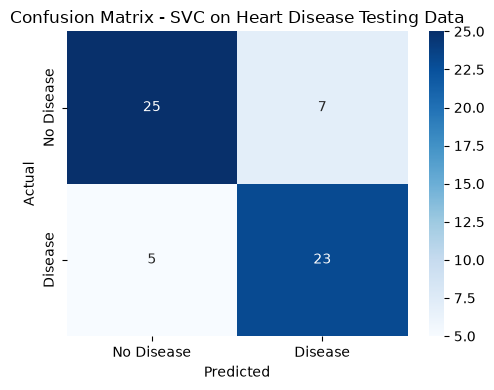

In [17]:
# Step 7.5: Detailed Evaluation Metrics (Precision, Recall, F1, Confusion Matrix)

print("\nClassification Report:")
print("=======================\n")
print(classification_report(
    model_predictions["HeartDisease"],
    model_predictions["Predictions"],
    target_names=["No Heart Disease (0)", "Heart Disease (1)"]
))

conf_matrix = confusion_matrix(model_predictions["HeartDisease"], model_predictions["Predictions"])
conf_matrix_df = pd.DataFrame(
    conf_matrix,
    index=["Actual: No Heart Disease", "Actual: Heart Disease"],
    columns=["Predicted: No Heart Disease", "Predicted: Heart Disease"]
)
print("\nConfusion Matrix:")
print("==================\n")
print(conf_matrix_df)

plt.figure(figsize=(5, 4))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No Disease", "Disease"],
            yticklabels=["No Disease", "Disease"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - SVC on Heart Disease Testing Data")
plt.tight_layout()
plt.show()


In [18]:
# Step 7.6: Cross-Validation Sanity Check

features_all = sample_data_encoded.iloc[:, :-1]
labels_all = sample_data_encoded.iloc[:, -1]

cv_scores = cross_val_score(
    svm.SVC(gamma="auto", random_state=0),
    features_all, labels_all,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
)

print("Accuracy in each of the 5 folds:", cv_scores.round(2))
print("Mean accuracy:", round(cv_scores.mean(), 2), "| Standard deviation:", round(cv_scores.std(), 2))


Accuracy in each of the 5 folds: [0.85 0.83 0.68 0.75 0.76]
Mean accuracy: 0.77 | Standard deviation: 0.06


In [19]:
# Step 8.1: Take Input from User
# To type your own values, replace the four lines below with:
# chest_pain_input = input("Please enter ChestPain here (Typical Angina, Atypical Angina, Non-anginal Pain, Asymptomatic): ").strip()
# exercise_angina_input = input("Please enter ExerciseAngina here (Yes, No): ").strip()
# major_vessels_input = input("Please enter MajorVessels here (0 Vessels, 1 Vessel, 2 Vessels, 3 Vessels): ").strip()
# thalassemia_input = input("Please enter Thalassemia here (Normal, Fixed Defect, Reversible Defect): ").strip()

# Demo patient (edit these values, or swap in input() calls as shown above)
chest_pain_input = "Asymptomatic"
exercise_angina_input = "Yes"
major_vessels_input = "2 Vessels"
thalassemia_input = "Reversible Defect"

print(f"ChestPain: {chest_pain_input}, ExerciseAngina: {exercise_angina_input}, "
      f"MajorVessels: {major_vessels_input}, Thalassemia: {thalassemia_input}")


ChestPain: Asymptomatic, ExerciseAngina: Yes, MajorVessels: 2 Vessels, Thalassemia: Reversible Defect


In [20]:
# Step 8.2: Convert User Input into Feature Vector (Exactly Same as Feature Vectors of Sample Data)

user_input = pd.DataFrame({
    "ChestPain": [chest_pain_input],
    "ExerciseAngina": [exercise_angina_input],
    "MajorVessels": [major_vessels_input],
    "Thalassemia": [thalassemia_input]
})

print("\n\nUser Input Feature Vector:")
print("==========================\n")
print(user_input)




User Input Feature Vector:

      ChestPain ExerciseAngina MajorVessels        Thalassemia
0  Asymptomatic            Yes    2 Vessels  Reversible Defect


In [21]:
# Step 8.3: Label Encoding of Feature Vector (Exactly Same as Label Encoded Feature Vectors of Sample Data)

unseen_data_features = user_input.copy()

unseen_data_features["ChestPain"] = chest_pain_label_encoder.transform(user_input["ChestPain"])
unseen_data_features["ExerciseAngina"] = exercise_angina_label_encoder.transform(user_input["ExerciseAngina"])
unseen_data_features["MajorVessels"] = major_vessels_label_encoder.transform(user_input["MajorVessels"])
unseen_data_features["Thalassemia"] = thalassemia_label_encoder.transform(user_input["Thalassemia"])

print("\n\nUser Input Encoded Feature Vector:")
print("==================================\n")
print(unseen_data_features)




User Input Encoded Feature Vector:

   ChestPain  ExerciseAngina  MajorVessels  Thalassemia
0          0               1             2            2


In [22]:
# Step 8.4: Load the Saved Model

model = pickle.load(open("svc_trained_model.pkl", "rb"))


In [23]:
# Step 8.5.1: Apply Model on the Label Encoded Feature Vector of unseen instance and return Prediction to the User

predicted_heart_disease = model.predict(unseen_data_features)

if predicted_heart_disease == 1:
    prediction = "HEART DISEASE LIKELY"
if predicted_heart_disease == 0:
    prediction = "HEART DISEASE NOT LIKELY"

pretty_table = PrettyTable()
pretty_table.add_column("       ** Prediction **       ", [prediction])

print(pretty_table)
print("(Educational model only - not a medical diagnosis.)")


+--------------------------------+
|        ** Prediction **        |
+--------------------------------+
|      HEART DISEASE LIKELY      |
+--------------------------------+
(Educational model only - not a medical diagnosis.)


In [24]:
# Step 9.1: Collect Feedback from Users and Domain Experts on Performance of the Model Deployed in the Real World

def predict_patient(chest_pain, exercise_angina, major_vessels, thalassemia):
    """Encode one patient with the trained encoders and return the model's Yes/No answer."""
    row = pd.DataFrame({
        "ChestPain": [chest_pain_label_encoder.transform([chest_pain])[0]],
        "ExerciseAngina": [exercise_angina_label_encoder.transform([exercise_angina])[0]],
        "MajorVessels": [major_vessels_label_encoder.transform([major_vessels])[0]],
        "Thalassemia": [thalassemia_label_encoder.transform([thalassemia])[0]],
    })
    return "Heart disease likely" if model.predict(row)[0] == 1 else "Not likely"

test_patients = [
    ("Typical Angina", "No", "0 Vessels", "Normal"),
    ("Asymptomatic", "Yes", "2 Vessels", "Reversible Defect"),
    ("Non-anginal Pain", "No", "1 Vessel", "Normal"),
]
expert_comments = [
    "Few risk markers present, so a low-risk answer is what we would expect.",
    "Several strong risk markers together, so a high-risk answer is what we would expect.",
    "Borderline case: one vessel affected but otherwise normal. Doctors would want more tests, not a Yes/No answer.",
]

example_feedback = pd.DataFrame({
    "Reviewer": ["Domain Expert (Cardiology)"] * 3,
    "Patient (ChestPain / ExerciseAngina / MajorVessels / Thalassemia)": [" / ".join(p) for p in test_patients],
    "Model prediction": [predict_patient(*p) for p in test_patients],
    "Expert comment (illustrative)": expert_comments,
})
print(example_feedback.to_string(index=False))


                  Reviewer Patient (ChestPain / ExerciseAngina / MajorVessels / Thalassemia)     Model prediction                                                                                  Expert comment (illustrative)
Domain Expert (Cardiology)                          Typical Angina / No / 0 Vessels / Normal           Not likely                                        Few risk markers present, so a low-risk answer is what we would expect.
Domain Expert (Cardiology)                Asymptomatic / Yes / 2 Vessels / Reversible Defect Heart disease likely                           Several strong risk markers together, so a high-risk answer is what we would expect.
Domain Expert (Cardiology)                         Non-anginal Pain / No / 1 Vessel / Normal           Not likely Borderline case: one vessel affected but otherwise normal. Doctors would want more tests, not a Yes/No answer.


In [25]:
# Step 9.2: Make a List of Potential Improvements

improvements = [
    "Use more attributes (age, maximum heart rate, ST depression, cholesterol, blood pressure) - the 4-input limit of this assignment leaves useful clinical information unused",
    "Add the three other UCI hospital files (Hungarian, Switzerland, VA Long Beach) to get about 920 patients instead of 297 and test on patients from different hospitals",
    "Use cross-validation and hyperparameter tuning (C, gamma, kernel) and compare more models (Logistic Regression, Random Forest)",
    "Do the attribute ranking of Step 4 inside the training data only, so the test data plays no part in choosing the attributes",
    "Return a risk probability instead of a hard Yes/No, because a doctor needs to know how sure the model is; and prefer a model with higher recall, because missing a sick patient costs more than a false alarm",
]
for i, item in enumerate(improvements, 1):
    print(f"{i}. {item}")


1. Use more attributes (age, maximum heart rate, ST depression, cholesterol, blood pressure) - the 4-input limit of this assignment leaves useful clinical information unused
2. Add the three other UCI hospital files (Hungarian, Switzerland, VA Long Beach) to get about 920 patients instead of 297 and test on patients from different hospitals
3. Use cross-validation and hyperparameter tuning (C, gamma, kernel) and compare more models (Logistic Regression, Random Forest)
4. Do the attribute ranking of Step 4 inside the training data only, so the test data plays no part in choosing the attributes
5. Return a risk probability instead of a hard Yes/No, because a doctor needs to know how sure the model is; and prefer a model with higher recall, because missing a sick patient costs more than a false alarm


In [26]:
# Step 9.3: Improve the Model Based on Feedback

print("Next version: add numeric attributes (age, thalach, oldpeak) and the other UCI hospitals, tune the SVC with cross-validation, "
      "and compare precision/recall before replacing svc_trained_model.pkl")


Next version: add numeric attributes (age, thalach, oldpeak) and the other UCI hospitals, tune the SVC with cross-validation, and compare precision/recall before replacing svc_trained_model.pkl
